# HW#6 – Compact Transformer language model on BeRP

**202315163 김소희**

BeRP 식당 대화 문장(`transcript.txt`)으로, 앞 단어들을 보고 다음 단어를 예측하는 언어 모델을 직접 만들어 학습한다.

- 모델: causal Transformer 블록 2개, 토큰 임베딩, 위치 임베딩, 어휘 출력층
- 데이터: 노트북의 학습 분할만 사용하고, 사전 학습된 가중치는 쓰지 않는다.
- 손실: next-token cross-entropy
- 점수: `points = min(30, 600 / (PPL × (max(params, 100000) / 1000000)^0.15))`

## 1. 데이터 준비와 채점 셀

- `score_LM.ipynb` 원본 그대로

In [1]:
import hashlib
import math
from pathlib import Path

import torch
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset

torch.manual_seed(2026)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONTEXT = 64
path = Path("transcript.txt")
if not path.exists():
    raise FileNotFoundError("Place BeRP transcript.txt beside this notebook")

records = []
for line in path.read_text(encoding="utf-8", errors="replace").splitlines():
    parts = line.strip().split(maxsplit=1)
    if len(parts) == 2 and parts[1].strip():
        records.append((parts[0], parts[1].lower().split()))

def bucket(record_id):
    return int.from_bytes(hashlib.sha256(record_id.encode()).digest()[:8], "big") % 10

train = [words for uid, words in records if bucket(uid) < 8]
val = [(uid, words) for uid, words in records if bucket(uid) == 8]
val.sort(key=lambda row: hashlib.sha256(row[0].encode()).digest())
val = [words for _, words in val]
assert train and val, "Expected nonempty training and validation splits"
# Bucket 9 is reserved for the instructor's final evaluation.

vocab = ["<pad>", "<bos>", "<eos>", "<unk>"]
vocab += sorted(set(w for sent in train for w in sent) - set(vocab))
stoi = {w: i for i, w in enumerate(vocab)}
PAD, BOS, EOS, UNK = (stoi[w] for w in vocab[:4])
VOCAB_SIZE = len(vocab)

class LMData(Dataset):
    def __init__(self, sentences):
        self.pairs = []
        for words in sentences:
            ids = [BOS] + [stoi.get(w, UNK) for w in words] + [EOS]
            for start in range(0, len(ids) - 1, CONTEXT):
                self.pairs.append((
                    torch.tensor(ids[start:start + CONTEXT]),
                    torch.tensor(ids[start + 1:start + CONTEXT + 1]),
                ))

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        return self.pairs[i]

def collate(batch):
    return tuple(pad_sequence(parts, batch_first=True, padding_value=PAD)
                 for parts in zip(*batch))

train_loader = DataLoader(LMData(train), batch_size=64, shuffle=True, collate_fn=collate)
quick_loader = DataLoader(LMData(val[:256]), batch_size=64, collate_fn=collate)
val_loader = DataLoader(LMData(val), batch_size=64, collate_fn=collate)
print(f"device={DEVICE}, vocab={VOCAB_SIZE}, train={len(train)}, val={len(val)}")

device=cpu, vocab=1809, train=6829, val=904


In [2]:
def score(model, loader):
    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if not 0 < params <= 2_000_000:
        raise ValueError(f"Parameter budget exceeded: {params:,} (limit 2,000,000)")
    device = next(model.parameters()).device
    was_training = model.training
    model.eval()
    nll, tokens = 0.0, 0
    try:
        with torch.inference_mode():
            for x, y in loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                if logits.shape != (x.size(0), x.size(1), VOCAB_SIZE):
                    raise ValueError("Expected logits (batch, time, VOCAB_SIZE)")
                nll += F.cross_entropy(
                    logits.reshape(-1, VOCAB_SIZE), y.reshape(-1),
                    ignore_index=PAD, reduction="sum",
                ).item()
                tokens += (y != PAD).sum().item()
    finally:
        model.train(was_training)
    ce = nll / tokens
    ppl = math.exp(ce)
    points = min(30.0, 600.0 / (ppl * (max(params, 100_000) / 1_000_000) ** 0.15))
    print(f"CE={ce:.3f} | PPL={ppl:.2f} | params={params:,} | score={points:.2f}/30")
    return {"ce": ce, "ppl": ppl, "params": params, "points": points}

## 2. 입력 길이 맞추기

제공된 데이터 셀을 그대로 쓰면 입력 `x`가 정답 `y`보다 항상 한 토큰 길다.

- `LMData`는 `x = ids[start:start+CONTEXT]`, `y = ids[start+1:start+CONTEXT+1]`로 자른다.
- 문장이 모두 `CONTEXT=64`보다 짧다. `<bos>`와 `<eos>`를 붙여도 가장 긴 문장이 46 토큰이다.
- 그래서 `x`에는 마지막 `<eos>`까지 들어가고, `y`는 그보다 하나 짧다.

이대로 두면 모델 출력과 정답의 길이가 달라서, `score`와 학습 모두 `cross_entropy`에서 `ValueError`가 난다.

제공 셀은 고치지 않고, 아래 셀에서 `x`의 마지막 토큰(`<eos>`)만 잘라 길이를 맞췄다. `<eos>` 뒤에는 맞혀야 할 단어가 없으므로 잘라도 된다. 결과적으로 `x = ids[:-1]`, `y = ids[1:]`가 된다. 정답 `y`는 건드리지 않았으므로 채점되는 토큰과 PPL 계산은 그대로이다.

In [3]:
for loader in (train_loader, quick_loader, val_loader):
    loader.dataset.pairs = [(x[:len(y)], y) for x, y in loader.dataset.pairs]

x, y = next(iter(val_loader))
print(x.shape, y.shape)

torch.Size([64, 18]) torch.Size([64, 18])


## 3. 모델

Transformer 블록 하나를 `TransformerBlock` 클래스로 만들고 2개를 이어 붙였다. 블록은 Multi-head self-attention, FFN, residual connection, LayerNorm으로 이루어진다.

- 입력: 토큰 임베딩 + 위치 임베딩. 위치 임베딩도 학습된다.
- Causal mask: 자기보다 뒤에 있는 단어를 보지 못하게 가린다. 행렬의 상삼각을 `True`로 만든다.
- Padding mask: `<pad>` 자리는 attention에서 제외한다.
- 출력층: `nn.Linear(embedding_dim, VOCAB_SIZE)`

In [4]:
import torch.nn as nn


class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, ff_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            batch_first=True
        )
        # W2 x ReLU(W1 x output_i + b1) + b2
        self.ffn = nn.Sequential(
            nn.Linear(embedding_dim, ff_dim),
            nn.ReLU(),
            nn.Linear(ff_dim, embedding_dim)
        )
        self.norm1 = nn.LayerNorm(embedding_dim)
        self.norm2 = nn.LayerNorm(embedding_dim)

    def forward(self, h, causal_mask, padding_mask):
        # Q, K, V 모두 같은 텐서 h를 사용한다 (self-attention).
        attn_output, _ = self.attention(
            h, h, h,
            attn_mask=causal_mask,
            key_padding_mask=padding_mask,
            need_weights=False
        )
        # Residual connection + LayerNorm
        h = self.norm1(h + attn_output)
        h = self.norm2(h + self.ffn(h))
        return h


class TransformerLanguageModel(nn.Module):
    def __init__(self, embedding_dim=64, num_heads=4, ff_dim=128, max_len=CONTEXT):
        super().__init__()
        self.token_embedding = nn.Embedding(VOCAB_SIZE, embedding_dim, padding_idx=PAD)
        self.position_embedding = nn.Embedding(max_len, embedding_dim)
        # Causal Transformer 블록 2개
        self.block1 = TransformerBlock(embedding_dim, num_heads, ff_dim)
        self.block2 = TransformerBlock(embedding_dim, num_heads, ff_dim)
        self.output = nn.Linear(embedding_dim, VOCAB_SIZE)

    def forward(self, x):
        batch_size, seq_len = x.shape

        # (seq_len,) -> (1, seq_len): 배치 간 broadcasting
        positions = torch.arange(seq_len, device=x.device).unsqueeze(0)
        h = self.token_embedding(x) + self.position_embedding(positions)

        # Attention하지 않을 위치를 True로 masking한다.
        causal_mask = torch.triu(
            torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool),
            diagonal=1
        )
        padding_mask = (x == PAD)

        h = self.block1(h, causal_mask, padding_mask)
        h = self.block2(h, causal_mask, padding_mask)

        # (batch, time, VOCAB_SIZE)
        return self.output(h)

모델이 뒤에 있는 단어를 정말 못 보는지 확인한다. 입력의 인덱스 5부터를 다른 토큰으로 바꿔도, 그 앞 위치의 logits는 똑같아야 한다.

In [5]:
check_model = TransformerLanguageModel().to(DEVICE)
check_model.eval()

x, y = next(iter(quick_loader))
x = x.to(DEVICE)
x_changed = x.clone()
x_changed[:, 5:] = UNK

with torch.no_grad():
    logits = check_model(x)
    logits_changed = check_model(x_changed)

print("logits:", logits.shape)
assert torch.allclose(logits[:, :5], logits_changed[:, :5], atol=1e-5)
print("미래 토큰을 바꿔도 앞 위치의 logits는 그대로이다.")

logits: torch.Size([64, 18, 1809])
미래 토큰을 바꿔도 앞 위치의 logits는 그대로이다.


## 4. 학습

- 손실: `nn.CrossEntropyLoss(ignore_index=PAD)`
- 옵티마이저: `AdamW`, 학습률 0.003. `weight_decay` 값을 함수 인자로 바꿀 수 있게 했다.
- 데이터: 제공된 `train_loader`(batch size 64)를 그대로 쓴다.
- epoch가 끝날 때마다 `score(model, quick_loader)`를 실행하고 PPL을 기록한다.

In [6]:
def train_model(embedding_dim, ff_dim, weight_decay=0.01, epochs=20, learning_rate=0.003):
    torch.manual_seed(0)
    model = TransformerLanguageModel(embedding_dim=embedding_dim, ff_dim=ff_dim).to(DEVICE)

    criterion = nn.CrossEntropyLoss(ignore_index=PAD)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay
    )

    quick_ppls = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for x, y in train_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()
            logits = model(x)
            # (batch * time, VOCAB_SIZE)와 (batch * time)으로 평탄화한다.
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1))
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch + 1:2d}, Loss {total_loss / len(train_loader):.4f} | quick: ", end="")
        quick_ppls.append(score(model, quick_loader)["ppl"])

    return model, quick_ppls

## 5. 설정 비교

`embedding_dim=64`, `ff_dim=128`, `num_heads=4`에서 시작해, 모델 크기와 weight decay를 바꾼 5가지 설정을 비교한다.

점수는 30점을 넘으면 30점으로 잘린다. 30점인 설정끼리도 비교하려고, 잘리기 전 점수(`raw`)를 함께 출력한다.

In [7]:
experiments = {
    "A: d=64, ff=128, wd=0.01": dict(embedding_dim=64, ff_dim=128, weight_decay=0.01),
    "B: d=64, ff=128, wd=0.3": dict(embedding_dim=64, ff_dim=128, weight_decay=0.3),
    "C: d=48, ff=96, wd=0.3": dict(embedding_dim=48, ff_dim=96, weight_decay=0.3),
    "D: d=32, ff=64, wd=0.3": dict(embedding_dim=32, ff_dim=64, weight_decay=0.3),
    "E: d=32, ff=64, wd=0.01": dict(embedding_dim=32, ff_dim=64, weight_decay=0.01),
}

models, curves, results = {}, {}, {}
for name, config in experiments.items():
    print(f"=== {name} ===")
    models[name], curves[name] = train_model(**config)
    print("full validation: ", end="")
    results[name] = score(models[name], val_loader)

=== A: d=64, ff=128, wd=0.01 ===


Epoch  1, Loss 4.3550 | quick: CE=3.623 | PPL=37.45 | params=304,401 | score=19.15/30


Epoch  2, Loss 3.2697 | quick: CE=3.330 | PPL=27.94 | params=304,401 | score=25.67/30


Epoch  3, Loss 2.9426 | quick: CE=3.194 | PPL=24.39 | params=304,401 | score=29.41/30


Epoch  4, Loss 2.7252 | quick: CE=3.164 | PPL=23.67 | params=304,401 | score=30.00/30


Epoch  5, Loss 2.5629 | quick: CE=3.163 | PPL=23.64 | params=304,401 | score=30.00/30


... (93 outputs left out)

Epoch 17, Loss 2.2381 | quick: CE=3.397 | PPL=29.87 | params=136,721 | score=27.07/30


Epoch 18, Loss 2.2164 | quick: CE=3.392 | PPL=29.74 | params=136,721 | score=27.20/30


Epoch 19, Loss 2.1878 | quick: CE=3.407 | PPL=30.16 | params=136,721 | score=26.81/30


Epoch 20, Loss 2.1638 | quick: CE=3.409 | PPL=30.23 | params=136,721 | score=26.75/30
full validation: CE=3.318 | PPL=27.59 | params=136,721 | score=29.31/30


In [8]:
print(f"{'설정':26} {'PPL':>7} {'params':>9} {'points':>7} {'raw':>7}")
for name, r in results.items():
    raw = 600.0 / (r["ppl"] * (max(r["params"], 100_000) / 1_000_000) ** 0.15)
    print(f"{name:26} {r['ppl']:7.2f} {r['params']:9,} {r['points']:7.2f} {raw:7.2f}")

설정                             PPL    params  points     raw
A: d=64, ff=128, wd=0.01     31.92   304,401   22.47   22.47
B: d=64, ff=128, wd=0.3      18.78   304,401   30.00   38.19
C: d=48, ff=96, wd=0.3       19.53   216,465   30.00   38.65
D: d=32, ff=64, wd=0.3       19.24   136,721   30.00   42.03
E: d=32, ff=64, wd=0.01      27.59   136,721   29.31   29.31


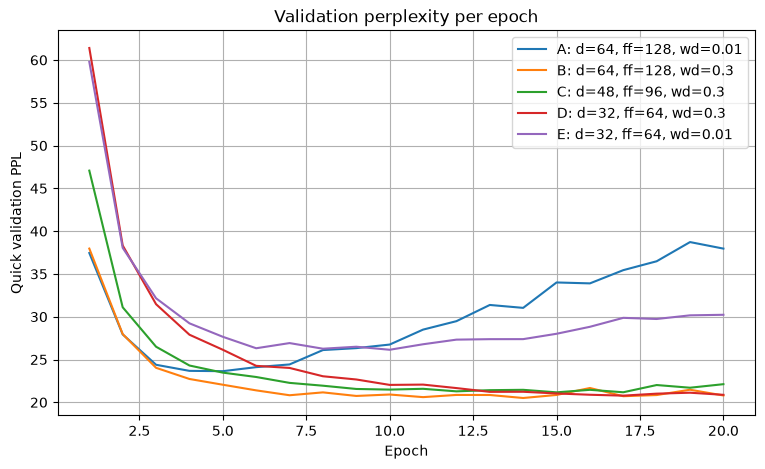

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for name, ppls in curves.items():
    plt.plot(range(1, len(ppls) + 1), ppls, label=name)

plt.xlabel("Epoch")
plt.ylabel("Quick validation PPL")
plt.title("Validation perplexity per epoch")
plt.legend()
plt.grid()
plt.show()

## 6. 최종 모델: 전체 검증 점수와 체크포인트 저장

In [10]:
FINAL = "D: d=32, ff=64, wd=0.3"
model = models[FINAL]
final = score(model, val_loader)

torch.save(
    {"config": experiments[FINAL], "vocab": vocab, "state_dict": model.state_dict()},
    "08_hw6_model.pt"
)

# 저장한 체크포인트를 다시 불러와 같은 점수가 나오는지 확인한다.
checkpoint = torch.load("08_hw6_model.pt", map_location=DEVICE)
reloaded = TransformerLanguageModel(
    embedding_dim=checkpoint["config"]["embedding_dim"],
    ff_dim=checkpoint["config"]["ff_dim"]
).to(DEVICE)
reloaded.load_state_dict(checkpoint["state_dict"])
assert abs(score(reloaded, val_loader)["ppl"] - final["ppl"]) < 1e-3

CE=2.957 | PPL=19.24 | params=136,721 | score=30.00/30
CE=2.957 | PPL=19.24 | params=136,721 | score=30.00/30


## 7. 결과와 분석

**최종 전체 검증 점수: PPL 19.24, 파라미터 136,721개, 30.00/30점** (CE 2.957, 30점으로 잘리기 전 점수 42.03)

최종 모델은 설정 D이다.

- 모델: causal Transformer 블록 2개, `embedding_dim=32`, `num_heads=4`, `ff_dim=64`
- 학습: AdamW(학습률 0.003, weight decay 0.3), batch size 64, 20 epoch

| 설정 | PPL | 파라미터 | points | 잘리기 전 점수 |
|---|---|---|---|---|
| A: d=64, ff=128, wd=0.01 | 31.92 | 304,401 | 22.47 | 22.47 |
| B: d=64, ff=128, wd=0.3 | 18.78 | 304,401 | 30.00 | 38.19 |
| C: d=48, ff=96, wd=0.3 | 19.53 | 216,465 | 30.00 | 38.65 |
| D: d=32, ff=64, wd=0.3 (최종) | 19.24 | 136,721 | 30.00 | 42.03 |
| E: d=32, ff=64, wd=0.01 | 27.59 | 136,721 | 29.31 | 29.31 |

### 도움이 된 변경 1: weight decay를 0.01에서 0.3으로 키움

- 가장 큰 모델에 weight decay 0.01을 쓴 A는 학습할수록 train loss가 1.66까지 내려갔다. 하지만 quick PPL은 5 epoch에서 23.64로 가장 낮았고, 20 epoch에는 37.96까지 올라갔다. 전체 검증 PPL은 31.92, 점수는 22.47점이었다.
- 학습 데이터는 점점 잘 맞히는데 검증 데이터는 점점 못 맞히므로 과적합이라고 판단했다. 학습 토큰이 약 5만 개로 적다.
- 같은 모델에서 weight decay만 0.3으로 바꾼 B는 quick PPL이 20 epoch까지 21 안팎에 머물렀고, 전체 검증 PPL은 18.78이었다.
- 작은 모델에서도 마찬가지였다. weight decay가 0.01인 E는 27.59, 0.3인 D는 19.24이다.

### 도움이 된 변경 2: 모델 크기를 줄임

- `embedding_dim`을 64에서 32로 줄이면(B에서 D로) PPL은 18.78에서 19.24로 조금 나빠진다.
- 대신 파라미터가 304,401개에서 136,721개로 줄어든다. 점수 식은 파라미터가 적을수록 점수를 더 주므로, 잘리기 전 점수는 38.19에서 42.03으로 올랐다.
- 어휘가 1,809개라서 파라미터 대부분이 임베딩과 출력층에 있다. 그래서 `embedding_dim`을 줄이면 파라미터가 크게 줄어든다.
- 모델이 작을수록 PPL이 꼭 나빠지는 것은 아니었다. C(d=48)가 D(d=32)보다 PPL이 조금 높다. 설정마다 한 번씩만 학습했기 때문에, 0.3 정도의 PPL 차이는 다시 실행하면 뒤바뀔 수 있다고 본다.

### 손해였던 것: weight decay 0.01로 오래 학습

- A와 E 모두 학습을 계속할수록 quick PPL이 나빠졌다. 가장 낮았던 때는 A가 5 epoch(23.64), E가 10 epoch(26.14)이다.
- 그 시점에서 학습을 멈춘 모델의 전체 검증 점수는 따로 재지 않았다.

체크포인트는 `08_hw6_model.pt`에 저장했다.